## 1. Import bibliotek

In [1]:
!pip install torch torchvision matplotlib

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


## 2. Stworzenie zbioru treningowego (jednego z augumentacją i jednego bez), walidacyjnego i testowego

In [3]:
mean, std = 0.2860, 0.3530

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])
train_tf_plain = test_tf

train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_plain = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=train_tf_plain)
train_aug   = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=train_tf_aug)
test_ds     = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)

g = torch.Generator().manual_seed(0)
targets = train_plain.targets
val_idx, tr_idx = [], []
for c in range(10):
    idx = (targets == c).nonzero(as_tuple=True)[0]
    idx = idx[torch.randperm(len(idx), generator=g)]
    val_idx += idx[:1000].tolist()
    tr_idx  += idx[1000:].tolist()

train_ds_plain = Subset(train_plain, tr_idx) # trening bez augmentacji
train_ds_aug   = Subset(train_aug,   tr_idx) # te same obrazy, z augmentacją
val_ds         = Subset(train_plain, val_idx) # walidacja test_tf

val_dl        = DataLoader(val_ds,         batch_size=256, shuffle=False)
train_eval_dl = DataLoader(train_ds_plain, batch_size=256, shuffle=False)
test_dl       = DataLoader(test_ds,        batch_size=256, shuffle=False)

print(len(train_ds_plain), len(val_ds), len(test_ds)) # 50000 10000 10000

50000 10000 10000


## 3. Stworzenie klasy MLP z parametrem p_drop umożliwiającym dodanie dropout'u

W klasie MLP wykorzystujemy warstwy ukryte hidden=(512, 256, 128), poniewż ten model wyszedł jako najlepszy w laboratorium 1.

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(512, 256, 128), n_classes=10, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## 4. Funkcja evaluate() i run_training()

In [5]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

In [6]:
def run_training(model, train_dl, val_dl, epochs=12, lr=1e-3,
                 weight_decay=0.0, optimizer="adam", verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    if optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    n = len(train_dl.dataset)

    for epoch in range(1, epochs + 1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item() * yb.numel()

        tr = run / n
        vl, va = evaluate(model, val_dl)
        hist["train_loss"].append(tr)
        hist["test_loss"].append(vl)
        hist["test_acc"].append(va)
        if verbose:
            print(f"Epoka {epoch:2d} | trening {tr:.3f} | val {vl:.3f} | accuracy {va*100:.2f}%")

    return hist

## 5. Trening modeli

In [7]:
EPOCHS = 12

# 1. Baseline (Model 3 z Lab 1), bez ulepszeń
print("Baseline: ")
torch.manual_seed(0)
base = MLP(p_drop=0.0)
tr_dl = DataLoader(train_ds_plain, batch_size=128, shuffle=True)
hist_base = run_training(base, tr_dl, val_dl, epochs=EPOCHS, lr=1e-3)
tr_eval_loss_base, _ = evaluate(base, train_eval_dl)
val_loss_base, val_acc_base = evaluate(base, val_dl)
gap_base = val_loss_base - tr_eval_loss_base
print(f"Baseline przerwa test-trening {gap_base:.3f}")
print(f"Baseline ostatnie accuracy: {val_acc_base*100:.2f}")

Baseline: 
Epoka  1 | trening 0.556 | val 0.491 | accuracy 83.25%
Epoka  2 | trening 0.479 | val 0.472 | accuracy 83.32%
Epoka  3 | trening 0.457 | val 0.465 | accuracy 83.90%
Epoka  4 | trening 0.444 | val 0.470 | accuracy 83.71%
Epoka  5 | trening 0.436 | val 0.465 | accuracy 84.03%
Epoka  6 | trening 0.433 | val 0.444 | accuracy 84.79%
Epoka  7 | trening 0.426 | val 0.462 | accuracy 83.56%
Epoka  8 | trening 0.423 | val 0.463 | accuracy 83.88%
Epoka  9 | trening 0.418 | val 0.446 | accuracy 84.50%
Epoka 10 | trening 0.413 | val 0.455 | accuracy 84.33%
Epoka 11 | trening 0.411 | val 0.441 | accuracy 84.95%
Epoka 12 | trening 0.410 | val 0.460 | accuracy 84.41%
Baseline przerwa test-trening 0.049
Baseline ostatnie accuracy: 84.41


In [8]:
# 2. Wariant A: tylko Dropout (p_drop=0.2)
print("Wariant A (p_drop=0.2): ")
torch.manual_seed(0)
model_a = MLP(p_drop=0.2)
tr_dl = DataLoader(train_ds_plain, batch_size=128, shuffle=True)
hist_a = run_training(model_a, tr_dl, val_dl, epochs=EPOCHS, lr=1e-3)
tr_eval_loss_a, _ = evaluate(model_a, train_eval_dl)
val_loss_a, val_acc_a = evaluate(model_a, val_dl)
gap_a = val_loss_a - tr_eval_loss_a
print(f"Wariant A przerwa test-trening: {gap_a:.3f}")
print(f"Wariant A ostatnie accuracy: {val_acc_a*100:.2f}")

Wariant A (p_drop=0.2): 
Epoka  1 | trening 0.592 | val 0.476 | accuracy 83.55%
Epoka  2 | trening 0.506 | val 0.475 | accuracy 83.54%
Epoka  3 | trening 0.486 | val 0.463 | accuracy 83.99%
Epoka  4 | trening 0.475 | val 0.492 | accuracy 83.10%
Epoka  5 | trening 0.472 | val 0.461 | accuracy 84.16%
Epoka  6 | trening 0.466 | val 0.460 | accuracy 83.95%
Epoka  7 | trening 0.467 | val 0.485 | accuracy 83.14%
Epoka  8 | trening 0.459 | val 0.479 | accuracy 83.61%
Epoka  9 | trening 0.460 | val 0.451 | accuracy 84.26%
Epoka 10 | trening 0.458 | val 0.484 | accuracy 83.72%
Epoka 11 | trening 0.455 | val 0.449 | accuracy 84.53%
Epoka 12 | trening 0.449 | val 0.472 | accuracy 84.22%
Wariant A przerwa test-trening: 0.044
Wariant A ostatnie accuracy: 84.22


In [9]:
# 3. Wariant B: zmiana optymalizatora na AdamW + weight_decay = 1e-2
print("Wariant B (AdamW, wd=1e-2): ")
torch.manual_seed(0)
model_b = MLP(p_drop=0.0)
tr_dl = DataLoader(train_ds_plain, batch_size=128, shuffle=True)
hist_b = run_training(model_b, tr_dl, val_dl, epochs=EPOCHS, lr=1e-3, optimizer="adamw", weight_decay=1e-2)
tr_eval_loss_b, _ = evaluate(model_b, train_eval_dl)
val_loss_b, val_acc_b = evaluate(model_b, val_dl)
gap_b = val_loss_b - tr_eval_loss_b
print(f"Wariant B przerwa test-trening: {gap_b:.3f}")
print(f"Wariant B ostatnie accuracy: {val_acc_b*100:.2f}")

Wariant B (AdamW, wd=1e-2): 
Epoka  1 | trening 0.556 | val 0.491 | accuracy 83.22%
Epoka  2 | trening 0.479 | val 0.472 | accuracy 83.31%
Epoka  3 | trening 0.457 | val 0.465 | accuracy 83.89%
Epoka  4 | trening 0.444 | val 0.470 | accuracy 83.73%
Epoka  5 | trening 0.436 | val 0.465 | accuracy 84.02%
Epoka  6 | trening 0.433 | val 0.444 | accuracy 84.76%
Epoka  7 | trening 0.427 | val 0.463 | accuracy 83.59%
Epoka  8 | trening 0.423 | val 0.463 | accuracy 83.85%
Epoka  9 | trening 0.419 | val 0.446 | accuracy 84.55%
Epoka 10 | trening 0.414 | val 0.454 | accuracy 84.31%
Epoka 11 | trening 0.411 | val 0.440 | accuracy 85.00%
Epoka 12 | trening 0.410 | val 0.460 | accuracy 84.42%
Wariant B przerwa test-trening: 0.049
Wariant B ostatnie accuracy: 84.42


In [10]:
# 4. Wariant C: augmentacja danych RandomHorizontalFlip
print("Wariant C (RandomHorizontalFlip): ")
torch.manual_seed(0)
model_c = MLP(p_drop=0.0)
tr_dl_aug = DataLoader(train_ds_aug, batch_size=128, shuffle=True)
hist_c = run_training(model_c, tr_dl_aug, val_dl, epochs=EPOCHS, lr=1e-3)
tr_eval_loss_c, _ = evaluate(model_c, train_eval_dl)
val_loss_c, val_acc_c = evaluate(model_c, val_dl)
gap_c = val_loss_c - tr_eval_loss_c
print(f"Wariant C przerwa test-trening: {gap_c:.3f}")
print(f"Wariant C ostatnie accuracy: {val_acc_c*100:.2f}")

Wariant C (RandomHorizontalFlip): 
Epoka  1 | trening 0.646 | val 0.558 | accuracy 80.96%
Epoka  2 | trening 0.573 | val 0.586 | accuracy 80.07%
Epoka  3 | trening 0.548 | val 0.550 | accuracy 81.37%
Epoka  4 | trening 0.538 | val 0.533 | accuracy 81.84%
Epoka  5 | trening 0.528 | val 0.530 | accuracy 81.77%
Epoka  6 | trening 0.525 | val 0.560 | accuracy 81.07%
Epoka  7 | trening 0.520 | val 0.520 | accuracy 82.15%
Epoka  8 | trening 0.515 | val 0.517 | accuracy 81.91%
Epoka  9 | trening 0.515 | val 0.530 | accuracy 82.04%
Epoka 10 | trening 0.509 | val 0.548 | accuracy 80.95%
Epoka 11 | trening 0.508 | val 0.566 | accuracy 81.10%
Epoka 12 | trening 0.505 | val 0.521 | accuracy 81.99%
Wariant C przerwa test-trening: 0.022
Wariant C ostatnie accuracy: 81.99


## 6. Zestawienie wyników w tabeli

In [11]:
results_df = pd.DataFrame({
    "Wariant": ["Baseline", "Wariant A", "Wariant B", "Wariant C"],
    "Opis zmiany": [
        "brak",
        "p_drop = 0.2",
        "AdamW, weight_decay = 1e-2",
        "RandomHorizontalFlip"
    ],
    "Val Accuracy (ost. epoka)": [
        f"{val_acc_base*100:.2f}%",
        f"{val_acc_a*100:.2f}%",
        f"{val_acc_b*100:.2f}%",
        f"{val_acc_c*100:.2f}%"
    ],

    "Przerwa test-trening": [
        f"{gap_base:.3f}",
        f"{gap_a:.3f}",
        f"{gap_b:.3f}",
        f"{gap_c:.3f}"
    ]
})
display(results_df)

,Wariant,Opis zmiany,Val Accuracy (ost. epoka),Przerwa test-trening
0,Baseline,brak,84.41%,0.049
1,Wariant A,p_drop = 0.2,84.22%,0.044
2,Wariant B,"AdamW, weight_decay = 1e-2",84.42%,0.049
3,Wariant C,RandomHorizontalFlip,81.99%,0.022


## 7. Krzywe uczenia dla najlepszego modelu

Zgodnie z wynikami tabeli, najwyższe accuracy, spośród wariantów A, B i C, w ostatniej epoce osiągnął wariant B (84.42%), więc dla niego tworzymy krzywe uczenia.

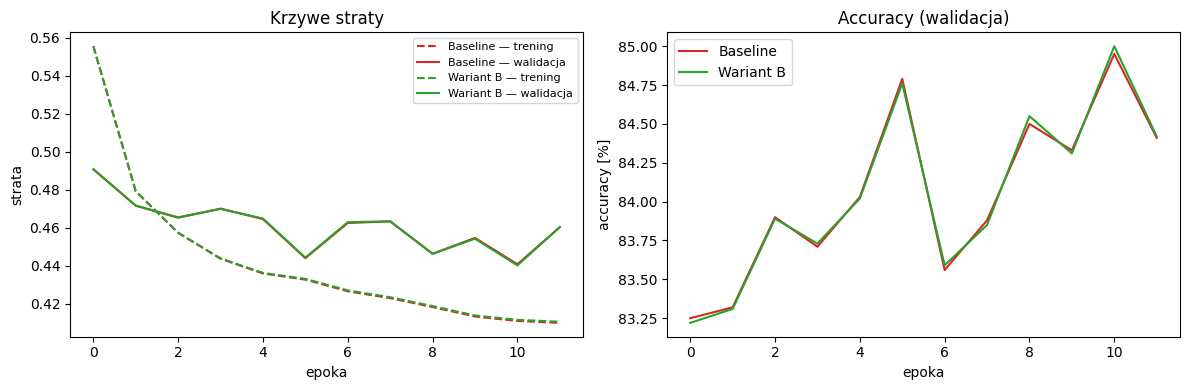

Baseline  | surowa przerwa wal-trening (strata): 0.050 | accuracy: 84.41%
Wariant B | surowa przerwa wal-trening (strata): 0.050 | accuracy: 84.42%


In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name, h, c in [("Baseline", hist_base, "tab:red"), ("Wariant B", hist_b, "tab:green")]:
    ax1.plot(h["train_loss"], "--", color=c, label=f"{name} — trening")
    ax1.plot(h["test_loss"],  "-",  color=c, label=f"{name} — walidacja")
    ax2.plot([a*100 for a in h["test_acc"]], color=c, label=name)

ax1.set_xlabel("epoka")
ax1.set_ylabel("strata")
ax1.legend(fontsize=8)
ax1.set_title("Krzywe straty")

ax2.set_xlabel("epoka")
ax2.set_ylabel("accuracy [%]")
ax2.legend()
ax2.set_title("Accuracy (walidacja)")

plt.tight_layout()
plt.show()

for name, h in [("Baseline", hist_base), ("Wariant B", hist_b)]:
    gap = h["test_loss"][-1] - h["train_loss"][-1]
    print(f"{name:9s} | surowa przerwa wal-trening (strata): {gap:.3f} | accuracy: {h['test_acc'][-1]*100:.2f}%")

## 8. Końcowa ocena na zbiorze testowym dla modelu Baseline i Wariantu B

In [13]:
test_loss_base, test_acc_base = evaluate(base, test_dl)
test_loss_best, test_acc_best = evaluate(model_b, test_dl)

print("Ostateczne wyniki na zbiorze testowym: ")
print(f"Baseline:  Accuracy: {test_acc_base*100:.2f}% | Strata: {test_loss_base:.3f}")
print(f"Wariant B: Accuracy: {test_acc_best*100:.2f}% | Strata: {test_loss_best:.3f}")

Ostateczne wyniki na zbiorze testowym: 
Baseline:  Accuracy: 83.03% | Strata: 0.492
Wariant B: Accuracy: 83.03% | Strata: 0.493
